In [ ]:
!nvidia-smi

Tue Oct 20 07:47:53 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   76C    P0             34W /   70W |     123MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import os, time, math
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
# TF ma zajmować pamięć GPU stopniowo - inaczej PyTorch nie dostanie pamięci
for _gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(_gpu, True)

import torch
import keras

# Tryb szybki: True = mniej danych i epok (praca bez GPU)
SZYBKI_TRYB = os.environ.get("DL_FAST", "0") == "1"
# SZYBKI_TRYB = True   # <- odkomentuj, jeśli pracujesz bez GPU

SEED = 42
keras.utils.set_random_seed(SEED)   # Python random + NumPy + TF
np.random.seed(SEED)
torch.manual_seed(SEED)

# Urządzenie dla PyTorch: GPU jeśli jest, w przeciwnym razie CPU
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("GPU widziane przez TensorFlow:", tf.config.list_physical_devices("GPU"))
print("CUDA dostępna w PyTorch      :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Karta:", torch.cuda.get_device_name(0))
print("DEVICE =", DEVICE)

GPU widziane przez TensorFlow: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
CUDA dostępna w PyTorch      : True
Karta: Tesla T4
DEVICE = cuda


In [ ]:
rng = np.random.default_rng(0)
batch_np = rng.normal(loc=[0.5, 0.2, -0.3], scale=[2.0, 0.5, 1.0],
                      size=(16, 32, 32, 3)).astype(np.float32)

# TODO: uzupełnij - standaryzacja w TF (z_tf, NHWC) i w PyTorch (z_pt, NCHW)
#TensorFlow
x_tf = tf.convert_to_tensor(batch_np)
mu_tf = tf.reduce_mean(x_tf, axis=[0, 1, 2], keepdims=True)
std_tf = tf.math.reduce_std(x_tf, axis=[0, 1, 2], keepdims=True)
z_tf = (x_tf - mu_tf) / std_tf

#PyTorch
x_pt = torch.from_numpy(batch_np).permute(0, 3, 1, 2)
mu_pt = x_pt.mean(dim=(0, 2, 3), keepdim=True)
std_pt = x_pt.std(dim=(0, 2, 3), correction=0, keepdim=True)
z_pt = (x_pt - mu_pt) / std_pt

In [ ]:
# Komórka sprawdzająca - nie zmieniaj
if z_tf is None or z_pt is None:
    print("Uzupełnij z_tf i z_pt.")
else:
    print("TF  średnie per kanał:", np.round(tf.reduce_mean(z_tf, axis=[0, 1, 2]).numpy(), 4))
    print("TF  std per kanał    :", np.round(tf.math.reduce_std(z_tf, axis=[0, 1, 2]).numpy(), 4))
    print("PT  średnie per kanał:", np.round(z_pt.mean(dim=(0, 2, 3)).numpy(), 4))
    z_pt_nhwc = z_pt.permute(0, 2, 3, 1).numpy()      # powrót do NHWC
    print("Zgodność TF vs PyTorch:", np.allclose(z_tf.numpy(), z_pt_nhwc, atol=1e-5))

TF  średnie per kanał: [ 0. -0.  0.]
TF  std per kanał    : [1. 1. 1.]
PT  średnie per kanał: [0. 0. 0.]
Zgodność TF vs PyTorch: True


In [ ]:
def pairwise_sq_dist_np(X, Y):
    x_sq = (X ** 2).sum(axis=1)[:, None]      # (n, 1)
    y_sq = (Y ** 2).sum(axis=1)[None, :]      # (1, m)
    D = x_sq + y_sq - 2.0 * (X @ Y.T)         # broadcasting -> (n, m)
    return np.maximum(D, 0.0)


def pairwise_sq_dist_torch(X, Y):
    x_sq = (X ** 2).sum(dim=1).unsqueeze(1)   # (n, 1)
    y_sq = (Y ** 2).sum(dim=1).unsqueeze(0)   # (1, m)
    D = x_sq + y_sq - 2.0 * (X @ Y.T)         # broadcasting -> (n, m)
    return torch.clamp(D, min=0.0)

In [ ]:
# Komórka sprawdzająca - wersja pętlowa jako wzorzec
def pairwise_sq_dist_loop(X, Y):
    D = np.zeros((len(X), len(Y)))
    for i in range(len(X)):
        for j in range(len(Y)):
            D[i, j] = np.sum((X[i] - Y[j]) ** 2)
    return D

Xs, Ys = np.random.rand(50, 8), np.random.rand(40, 8)
D_ref = pairwise_sq_dist_loop(Xs, Ys)
D_np = pairwise_sq_dist_np(Xs, Ys)
D_pt = pairwise_sq_dist_torch(torch.from_numpy(Xs), torch.from_numpy(Ys))
if D_np is not None and D_pt is not None:
    print("NumPy - zgodność z wersją pętlową:", np.allclose(D_ref, D_np))
    print("Torch - zgodność z wersją pętlową:", np.allclose(D_ref, D_pt.numpy()))

    # Pomiar czasu: pętla vs wektoryzacja
    n_big = 150 if SZYBKI_TRYB else 400
    Xb, Yb = np.random.rand(n_big, 32), np.random.rand(n_big, 32)
    t0 = time.perf_counter(); pairwise_sq_dist_loop(Xb, Yb); t_loop = time.perf_counter() - t0
    t0 = time.perf_counter(); pairwise_sq_dist_np(Xb, Yb); t_vec = time.perf_counter() - t0
    print(f"n = {n_big}: pętla {t_loop:.3f} s, wektorowo {t_vec:.5f} s, przyspieszenie ~{t_loop / max(t_vec, 1e-9):.0f}x")

NumPy - zgodność z wersją pętlową: True
Torch - zgodność z wersją pętlową: True
n = 400: pętla 0.805 s, wektorowo 0.00159 s, przyspieszenie ~507x


In [ ]:
x0, y0 = 0.5, -1.0

# f(x, y) = sin(x) * y^2 + exp(x*y)
df_dx_analit = lambda x, y: np.cos(x) * y**2 + y * np.exp(x * y)
df_dy_analit = lambda x, y: 2 * np.sin(x) * y + x * np.exp(x * y)

#TensorFlow
x_tf = tf.Variable(x0, dtype=tf.float64)
y_tf = tf.Variable(y0, dtype=tf.float64)
with tf.GradientTape() as tape:
    f_tf = tf.sin(x_tf) * y_tf**2 + tf.exp(x_tf * y_tf)
grad_tf = [g.numpy() for g in tape.gradient(f_tf, [x_tf, y_tf])]   # [df/dx, df/dy]

#PyTorch
x_pt = torch.tensor(x0, dtype=torch.float64, requires_grad=True)
y_pt = torch.tensor(y0, dtype=torch.float64, requires_grad=True)
f_pt = torch.sin(x_pt) * y_pt**2 + torch.exp(x_pt * y_pt)
f_pt.backward()
grad_pt = [x_pt.grad.item(), y_pt.grad.item()]                    # [df/dx, df/dy]

if grad_tf is not None and grad_pt is not None and df_dx_analit is not None:
    print("analitycznie:", df_dx_analit(x0, y0), df_dy_analit(x0, y0))
    print("TF          :", grad_tf)
    print("PyTorch     :", grad_pt)

analitycznie: 0.27105190217773933 -0.6555857473520893
TF          : [np.float64(0.27105190217773933), np.float64(-0.6555857473520893)]
PyTorch     : [0.27105190217773933, -0.6555857473520893]


In [ ]:
def grad_numeryczny(f, w, h=1e-5):
    w = np.asarray(w, dtype=np.float64)
    g = np.zeros_like(w, dtype=np.float64)
    for i in range(w.size):
        e = np.zeros_like(w)
        e[i] = 1.0
        g[i] = (f(w + h * e) - f(w - h * e)) / (2.0 * h)   # różnica centralna
    return g

autograd : [-3.226934 -2.06264  -0.560624  0.037266]
numeryczny: [-3.226934 -2.06264  -0.560624  0.037266]
błąd względny (h=1e-5): 1.466103031535036e-11


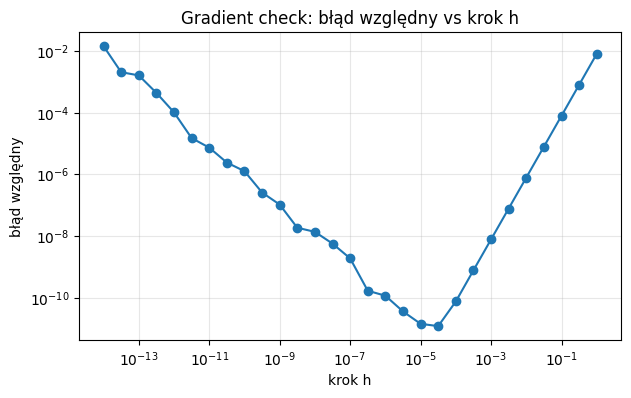

In [ ]:
rng = np.random.default_rng(1)
A_mat = rng.normal(size=(6, 4))
w0 = rng.normal(size=4)

def f_np(w):                                   # wersja NumPy (do różnic skończonych)
    z = A_mat @ w
    return np.log(np.sum(np.exp(z))) + 0.5 * np.sum(w ** 2)

# Gradient z autograd (PyTorch, float64)
w_t = torch.tensor(w0, dtype=torch.float64, requires_grad=True)
f_t = torch.logsumexp(torch.tensor(A_mat) @ w_t, dim=0) + 0.5 * (w_t ** 2).sum()
f_t.backward()
g_auto = w_t.grad.numpy()

def blad_wzgledny(a, b):
    return np.linalg.norm(a - b) / (np.linalg.norm(a) + np.linalg.norm(b) + 1e-300)

g_num = grad_numeryczny(f_np, w0, h=1e-5)
print("autograd :", np.round(g_auto, 6))
print("numeryczny:", np.round(g_num, 6))
print("błąd względny (h=1e-5):", blad_wzgledny(g_num, g_auto))

# Błąd w funkcji kroku h
hs = np.logspace(-14, 0, 29)
bledy = [blad_wzgledny(grad_numeryczny(f_np, w0, h), g_auto) for h in hs]
plt.figure(figsize=(7, 4))
plt.loglog(hs, np.maximum(bledy, 1e-17), "o-")
plt.title("Gradient check: błąd względny vs krok h")
plt.xlabel("krok h"); plt.ylabel("błąd względny"); plt.grid(alpha=0.3, which="both"); plt.show()

In [ ]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

dom = fetch_california_housing()
X_all, y_all = dom.data.astype(np.float64), dom.target.astype(np.float64)
if SZYBKI_TRYB:                       # tryb szybki: tylko 2000 pierwszych próbek
    X_all, y_all = X_all[:2000], y_all[:2000]
print("cechy:", list(dom.feature_names))
print("X:", X_all.shape, " y:", y_all.shape)

X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_all, test_size=0.2, random_state=SEED)

# Standaryzacja - statystyki TYLKO ze zbioru treningowego
mu, sigma = X_tr.mean(axis=0), X_tr.std(axis=0)
X_tr_s = (X_tr - mu) / sigma
X_te_s = (X_te - mu) / sigma
n_tr, d = X_tr_s.shape
print("train:", X_tr_s.shape, " test:", X_te_s.shape)
print("średnie cech po standaryzacji (train):", np.round(X_tr_s.mean(axis=0), 3))

cechy: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
X: (20640, 8)  y: (20640,)
train: (16512, 8)  test: (4128, 8)
średnie cech po standaryzacji (train): [-0. -0.  0. -0. -0. -0.  0. -0.]


In [ ]:
def mse(y_true, y_pred):
    return float(np.mean((y_true - y_pred) ** 2))

# Baseline: stała = średnia z treningu
print("Baseline (średnia) MSE test:", round(mse(y_te, np.full_like(y_te, y_tr.mean())), 4))

# Rozwiązanie analityczne (najmniejsze kwadraty) - dokładne minimum na train
Xb_tr = np.hstack([X_tr_s, np.ones((n_tr, 1))])          # kolumna jedynek = bias
theta_ls = np.linalg.lstsq(Xb_tr, y_tr, rcond=None)[0]
w_ls, b_ls = theta_ls[:-1], theta_ls[-1]
loss_opt = mse(y_tr, X_tr_s @ w_ls + b_ls)
print("Najmniejsze kwadraty: MSE train =", round(loss_opt, 4),
      " MSE test =", round(mse(y_te, X_te_s @ w_ls + b_ls), 4))

Baseline (średnia) MSE test: 1.3107
Najmniejsze kwadraty: MSE train = 0.5179  MSE test = 0.5559


In [ ]:
EPOKI_GD = 50 if SZYBKI_TRYB else 500

def gd_linreg(X, y, lr=0.2, epoki=EPOKI_GD):
    n, d = X.shape
    w = np.zeros(d)
    b = 0.0
    historia = []
    for ep in range(epoki):
        y_hat = X @ w + b                    # (n,)
        err = y_hat - y                      # (n,)
        historia.append(np.mean(err ** 2))   # MSE przed aktualizacją
        grad_w = (2.0 / n) * (X.T @ err)     # (d,)
        grad_b = (2.0 / n) * err.sum()       # skalar
        w = w - lr * grad_w
        b = b - lr * grad_b
    return w, b, historia

czas: 0.14 s
MSE train GD = 0.5179  vs  optimum = 0.5179  (różnica 0.00%)
MSE test GD  = 0.5559
max |w_gd - w_ls| = 0.0


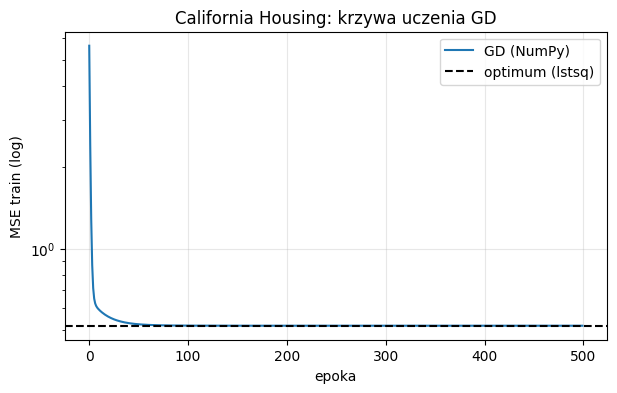

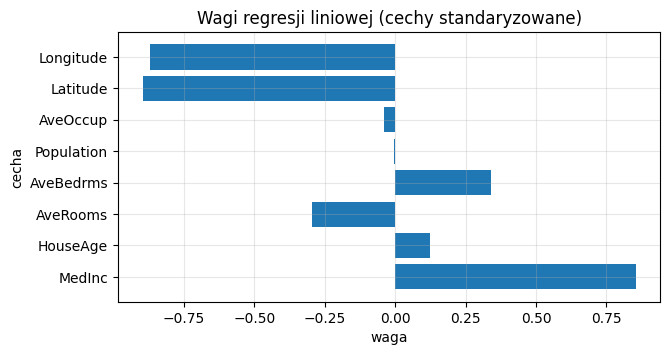

In [ ]:
t0 = time.perf_counter()
w_gd, b_gd, hist_gd = gd_linreg(X_tr_s, y_tr, lr=0.2, epoki=EPOKI_GD)
print(f"czas: {time.perf_counter() - t0:.2f} s")
if len(hist_gd) > 0:
    print(f"MSE train GD = {hist_gd[-1]:.4f}  vs  optimum = {loss_opt:.4f}  (różnica {100 * (hist_gd[-1] / loss_opt - 1):.2f}%)")
    print("MSE test GD  =", round(mse(y_te, X_te_s @ w_gd + b_gd), 4))
    print("max |w_gd - w_ls| =", np.abs(w_gd - w_ls).max().round(4))

    plt.figure(figsize=(7, 4))
    plt.plot(hist_gd, label="GD (NumPy)")
    plt.axhline(loss_opt, color="k", ls="--", label="optimum (lstsq)")
    plt.yscale("log"); plt.title("California Housing: krzywa uczenia GD")
    plt.xlabel("epoka"); plt.ylabel("MSE train (log)"); plt.legend(); plt.grid(alpha=0.3); plt.show()

    # Które cechy mają największy wpływ? (cechy są standaryzowane, więc wagi są porównywalne)
    plt.figure(figsize=(7, 3.5))
    plt.barh(dom.feature_names, w_gd)
    plt.title("Wagi regresji liniowej (cechy standaryzowane)"); plt.xlabel("waga"); plt.ylabel("cecha")
    plt.grid(alpha=0.3); plt.show()

In [ ]:
Xtr_tf = tf.constant(X_tr_s, dtype=tf.float32)
ytr_tf = tf.constant(y_tr, dtype=tf.float32)

d = Xtr_tf.shape[1]
w_tf = tf.Variable(tf.zeros(d, dtype=tf.float32))   # (d,)
b_tf = tf.Variable(0.0, dtype=tf.float32)           # skalar
lr = 0.2
hist_tf = []

for ep in range(EPOKI_GD):
    with tf.GradientTape() as tape:
        y_hat = tf.linalg.matvec(Xtr_tf, w_tf) + b_tf          # (n,)
        loss = tf.reduce_mean((y_hat - ytr_tf) ** 2)           # MSE
    grad_w, grad_b = tape.gradient(loss, [w_tf, b_tf])
    w_tf.assign_sub(lr * grad_w)
    b_tf.assign_sub(lr * grad_b)
    hist_tf.append(float(loss))                                # strata sprzed aktualizacji

In [ ]:
Xb = np.hstack([X_tr_s, np.ones((X_tr_s.shape[0], 1))])     # (n, d+1) - kolumna jedynek na bias
H = (2.0 / Xb.shape[0]) * (Xb.T @ Xb)                       # (d+1, d+1), symetryczny
eig = np.linalg.eigvalsh(H)                                 # rosnąco
lam_min, lam_max = eig[0], eig[-1]
lr_kryt = 2.0 / lam_max
print(f"lambda_min = {lam_min:.4f}, lambda_max = {lam_max:.4f}, uwarunkowanie = {lam_max / lam_min:.1f}")
print(f"teoretyczny próg rozbieżności lr_kryt = 2/lambda_max = {lr_kryt:.4f}")

EPOKI_LR = 40 if SZYBKI_TRYB else 200
lrs = [0.001, 0.01, 0.1, round(0.5 * lr_kryt, 4), round(0.98 * lr_kryt, 4), round(1.05 * lr_kryt, 4)]
historie = {}
for lr_ in lrs:
    with np.errstate(over="ignore", invalid="ignore"):      # rozbieżny przebieg może dać overflow
        _, _, hist = gd_linreg(X_tr_s, y_tr, lr=lr_, epoki=EPOKI_LR)
    historie[lr_] = hist

lambda_min = 0.0946, lambda_max = 4.0502, uwarunkowanie = 42.8
teoretyczny próg rozbieżności lr_kryt = 2/lambda_max = 0.4938


In [ ]:
def minibatch_gd(X, y, lr=0.05, epoki=20, batch_size=32, seed=0):
    rng = np.random.default_rng(seed)
    n, d = X.shape
    w = np.zeros(d)
    b = 0.0
    historia, czasy = [], []
    t0 = time.perf_counter()
    for ep in range(epoki):
        perm = rng.permutation(n)                            # nowa kolejność próbek w każdej epoce
        for start in range(0, n, batch_size):
            idx = perm[start:start + batch_size]             # ostatni batch może być mniejszy
            Xb, yb = X[idx], y[idx]
            err = Xb @ w + b - yb                            # (len(idx),)
            grad_w = (2.0 / len(idx)) * (Xb.T @ err)         # (d,)
            grad_b = (2.0 / len(idx)) * err.sum()            # skalar
            w = w - lr * grad_w
            b = b - lr * grad_b
        historia.append(np.mean((X @ w + b - y) ** 2))       # strata na całym zbiorze train
        czasy.append(time.perf_counter() - t0)
    return w, b, historia, czasy

    B = 16: kroków/epokę =  1032, MSE końcowe = 1348472944512236411869347210393665629960941032985433268774757977997108719943787295741578397353281843916993107769107683585726763150824056616206247160981277283505802293617302213374845908660135168256963084633809816158831914010932150272.0000, czas = 0.50 s
    B = 64: kroków/epokę =   258, MSE końcowe = 4456279472705809640092580406772873525371564950793260419812073400023035949547289329386127360.0000, czas = 0.15 s
   B = 256: kroków/epokę =    65, MSE końcowe = 0.5208, czas = 0.06 s
full-batch: kroków/epokę =     1, MSE końcowe = 0.6159, czas = 0.03 s


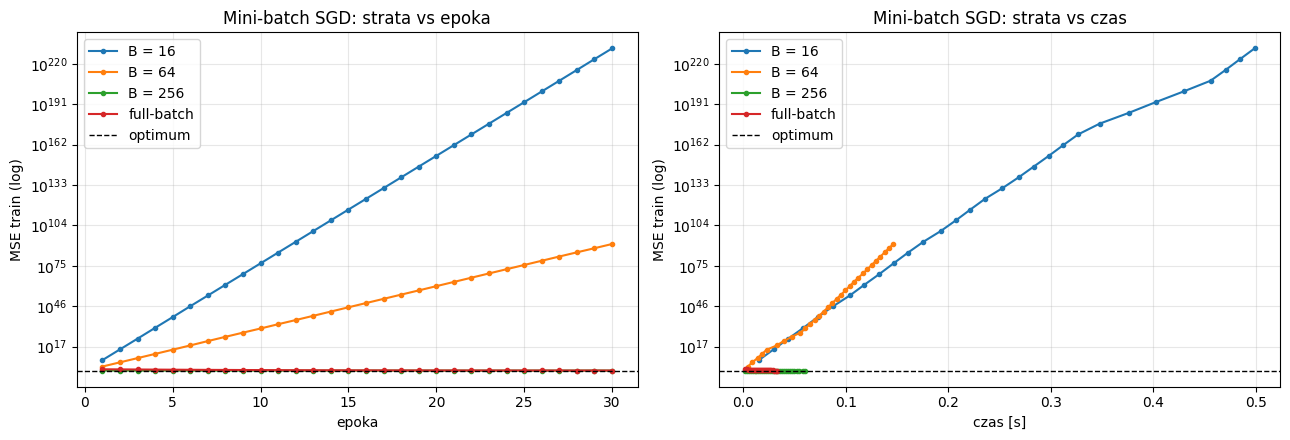

In [ ]:
EPOKI_MB = 4 if SZYBKI_TRYB else 30
wyniki_mb = {}
for bs in [16, 64, 256, n_tr]:
    _, _, h, c = minibatch_gd(X_tr_s, y_tr, lr=0.05, epoki=EPOKI_MB, batch_size=bs)
    nazwa = "full-batch" if bs == n_tr else f"B = {bs}"
    wyniki_mb[nazwa] = (h, c)
    print(f"{nazwa:>10}: kroków/epokę = {math.ceil(n_tr / bs):5d}, MSE końcowe = {h[-1]:.4f}, czas = {c[-1]:.2f} s")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for nazwa, (h, c) in wyniki_mb.items():
    ax[0].plot(range(1, len(h) + 1), h, "o-", ms=3, label=nazwa)
    ax[1].plot(c, h, "o-", ms=3, label=nazwa)
for a_, xl in zip(ax, ["epoka", "czas [s]"]):
    a_.axhline(loss_opt, color="k", ls="--", lw=1, label="optimum")
    a_.set_yscale("log"); a_.set_xlabel(xl); a_.set_ylabel("MSE train (log)"); a_.grid(alpha=0.3, which="both"); a_.legend()
ax[0].set_title("Mini-batch SGD: strata vs epoka"); ax[1].set_title("Mini-batch SGD: strata vs czas")
plt.tight_layout(); plt.show()

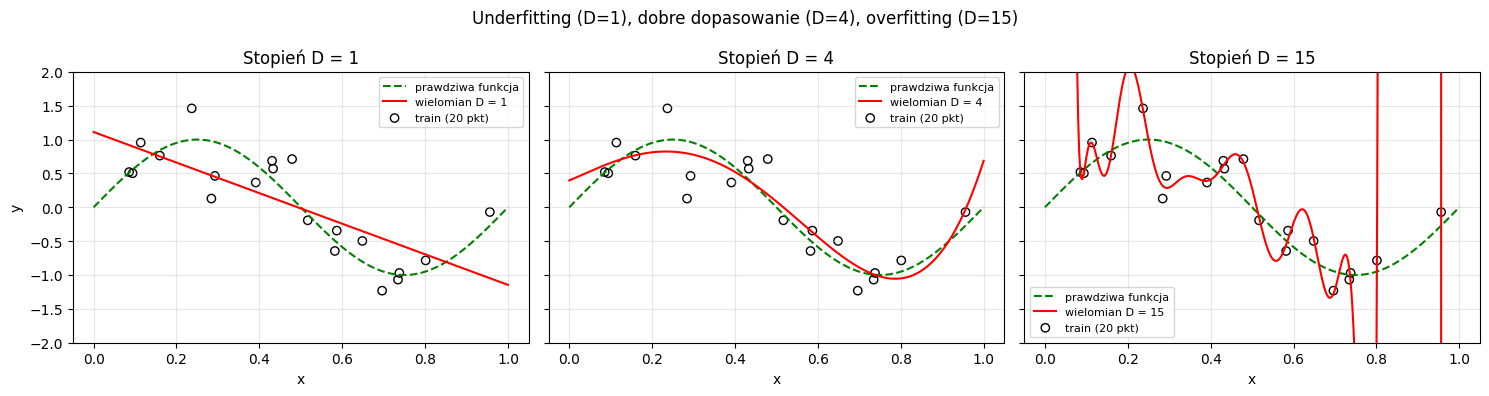

In [ ]:
rng = np.random.default_rng(3)
def prawdziwa_f(x):
    return np.sin(2 * np.pi * x)

n_train_p, n_val_p = 20, 200
x_trp = rng.uniform(0, 1, n_train_p); y_trp = prawdziwa_f(x_trp) + rng.normal(scale=0.3, size=n_train_p)
x_vap = rng.uniform(0, 1, n_val_p);   y_vap = prawdziwa_f(x_vap) + rng.normal(scale=0.3, size=n_val_p)

def poly_features(x, stopien):
    # Macierz Vandermonde'a: kolumny 1, x, x^2, ..., x^stopien
    return np.vander(x, stopien + 1, increasing=True)

def dopasuj_wielomian(x, y, stopien):
    Phi = poly_features(x, stopien)
    return np.linalg.lstsq(Phi, y, rcond=None)[0]       # najmniejsze kwadraty

xx = np.linspace(0, 1, 400)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax_, D in zip(axes, [1, 4, 15]):
    wD = dopasuj_wielomian(x_trp, y_trp, D)
    ax_.plot(xx, prawdziwa_f(xx), "g--", label="prawdziwa funkcja")
    ax_.plot(xx, poly_features(xx, D) @ wD, "r", label=f"wielomian D = {D}")
    ax_.scatter(x_trp, y_trp, edgecolors="k", facecolors="none", label="train (20 pkt)")
    ax_.set_ylim(-2, 2); ax_.set_title(f"Stopień D = {D}"); ax_.set_xlabel("x"); ax_.grid(alpha=0.3); ax_.legend(fontsize=8)
axes[0].set_ylabel("y")
plt.suptitle("Underfitting (D=1), dobre dopasowanie (D=4), overfitting (D=15)"); plt.tight_layout(); plt.show()